# 第195章: スコアマッチングと拡散モデルの統合

## Denoising Score Matching and What Diffusion Models Really Learn

---

### このノートブックの位置づけ — Unit 17 の山場

190 から 194 までで、2つの道を別々に歩いてきました。

| 道 | 到達点 | 残った困難 |
|---|---|---|
| **フロー**（190-191） | $d=196$ の画像で厳密尤度 2.6552 bits/dim | アーキテクチャが可逆性に縛られる |
| **EBM**（193-194） | 2次元で下限まで 0.0033 nats | $Z$ が計算できず、サンプラーが弱いと崩壊（CD-1 で $4.4\times10^9$） |

194 の最後で、EBM の困難に効いた**唯一の構造的な工夫**は焼きなましでした。
そして「ノイズの大きい状態から始めて徐々に下げる」という形が、
拡散モデル（37-45）の逆過程とそっくりだと気づいたところで終わりました。

**本章はこの符合が偶然でないことを示します。** 示す順番はこうです。

1. スコア $\nabla_x \log p$ を**直接学ぶ**目的関数（スコアマッチング）を作る
2. 素朴な形は**ヤコビアンのトレース**が必要で高コスト → 実測する
3. **ノイズを足せばトレースが消える**（デノイジングスコアマッチング）→ 恒等式を数値検証
4. **DDPM のノイズ予測 $\epsilon_\theta$ は、係数まで含めてスコアそのもの**だと数値検証
5. DSM で EBM を学習する — **$Z$ も負のサンプルも要らない**
6. ノイズレベル別のスコアで焼きなまし → **194 の困難が解消する量を測る**

結論を先に書きます。**37-45 で実装した拡散モデルは、EBM のスコアを
ノイズレベルごとに学習し、焼きなましでサンプリングするものでした。**
本章を読むと、既に書いたコードの意味が変わります。

### 学習目標

- [ ] 明示的スコアマッチングの目的関数を書き、$\mathrm{tr}(\nabla_x s_\theta)$ のコストを実測できる
- [ ] デノイジングスコアマッチングの恒等式 $\nabla_{\tilde x}\log p_\sigma(\tilde x) = \mathbb{E}[(x - \tilde x)/\sigma^2 \mid \tilde x]$ を数値検証できる
- [ ] DDPM のノイズ予測とスコアの関係 $\epsilon_\theta = -\sqrt{1-\bar\alpha}\,s_\theta$ を**係数込みで**確認できる
- [ ] DSM でエネルギー関数を学習し、193（厳密最尤）・194（CD）と同じ尺度で比較できる
- [ ] ノイズレベル $\sigma$ の選択がバイアスと分散のトレードオフであることを測定できる
- [ ] ノイズレベル別スコア + 焼きなましが 194 の混合問題をどれだけ改善するか、**同一計算予算で**測れる
- [ ] 生成モデル3系統（フロー・EBM・拡散）の関係を1枚で説明できる

### 前提知識

| ノートブック | トピック |
|---|---|
| **193** | **EBM・スコアが $Z$ なしで出ること** |
| **194** | **ランジュバン動力学・焼きなまし・CD** |
| **39-40** | **拡散モデルの理論（$x_t = \sqrt{\bar\alpha}x_0 + \sqrt{1-\bar\alpha}\epsilon$）** |
| 42 | 拡散モデル実装（ノイズ予測ネットワーク） |
| 190 | 変数変換（厳密尤度の基準） |
| 33 | 混合ガウス（目標分布。畳み込んでも混合ガウスなので解析解が使える） |

**難易度**: ★★★★★ | **所要時間**: 180-240分

> ⏱ **実行時間**: CPU で約4分です。

## 目次

1. [環境セットアップ](#setup)
2. [スコアを直接学ぶ — 明示的スコアマッチングとそのコスト](#esm)
3. [デノイジングスコアマッチングの恒等式](#dsm)
4. [ノイズ予測はスコア学習である](#noise-is-score)
5. [DSM で EBM を学習する — Z も負のサンプルも要らない](#train-ebm)
6. [ノイズレベル別スコア + 焼きなまし](#annealed)
7. [3系統の統合](#summary)
8. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)
print("numpy:", np.__version__)

torch: 2.9.1
numpy: 2.2.6


<a id="esm"></a>
## 2. スコアを直接学ぶ — 明示的スコアマッチングとそのコスト

193 で確かめたとおり、スコアは $Z$ なしで出ます。

$$\nabla_x \log p(x) = -\nabla_x E(x)$$

ならば**スコアそのものを学習目標にすれば $Z$ を回避できる**はずです。
素直に書くとこうなります。

$$J_{\text{naive}}(\theta)
= \tfrac{1}{2}\,\mathbb{E}_{x \sim p_{\text{data}}}
\big\|\, s_\theta(x) - \nabla_x \log p_{\text{data}}(x)\,\big\|^2$$

しかし右の $\nabla_x \log p_{\text{data}}$ は**分かりません**（それを知りたいのです）。

Hyvärinen (2005) は、部分積分でこれを計算可能な形に書き換えました。

$$J_{\text{ESM}}(\theta) = \mathbb{E}_{x \sim p_{\text{data}}}
\Big[\tfrac{1}{2}\|s_\theta(x)\|^2 + \mathrm{tr}\big(\nabla_x s_\theta(x)\big)\Big]
+ \text{const}$$

**データのスコアが消えました。** これが明示的スコアマッチング（ESM）です。

### 代償: ヤコビアンのトレース

$\mathrm{tr}(\nabla_x s_\theta)$ は $d \times d$ ヤコビアンの対角和です。
自動微分では**$d$ 回の逆伝播**が必要です（1成分ずつ）。
$d$ に比例して重くなります。

190 で「行列式が $O(d^3)$ だから三角にした」のと同じ構図です。
ここでは**トレースが $O(d)$ 回の逆伝播**になります。測ります。

In [2]:
# ============================================================
# 明示的スコアマッチング（ESM）のコスト: tr(∇s) に d 回の逆伝播
# ============================================================

class ScoreNet(nn.Module):
    def __init__(self, d, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, d),
        )

    def forward(self, x):
        return self.net(x)


def esm_loss(net, x):
    # (1/2)||s||^2 + tr(∇s)。トレースは成分ごとに d 回 backward する
    x = x.detach().requires_grad_(True)
    s = net(x)
    trace = 0.0
    for i in range(x.shape[1]):
        gi = torch.autograd.grad(s[:, i].sum(), x, retain_graph=True)[0]
        trace = trace + gi[:, i]
    return (0.5 * (s**2).sum(-1) + trace).mean()


def dsm_loss(net, x, sigma=0.1):
    # ノイズを足して「足したノイズ」を当てる。トレースは要らない
    eps = torch.randn_like(x)
    x_tilde = x + sigma * eps
    s = net(x_tilde)
    return ((sigma * s + eps) ** 2).sum(-1).mean()


def bench(fn, reps=20):
    for _ in range(3):      # ウォームアップ（190 で学んだ通り）
        fn()
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps

cost_rows = []
for d in [2, 8, 32, 128, 512]:
    net = ScoreNet(d)
    x = torch.randn(64, d)

    def run_esm():
        net.zero_grad()
        esm_loss(net, x).backward()

    def run_dsm():
        net.zero_grad()
        dsm_loss(net, x).backward()

    t_esm = bench(run_esm)
    t_dsm = bench(run_dsm)
    cost_rows.append((d, t_esm, t_dsm))
    print(f"d = {d:4d}: 明示的SM（trace）{t_esm*1000:8.2f} ms   "
          f"DSM {t_dsm*1000:6.2f} ms   比 {t_esm/t_dsm:7.1f}x")

print()
print("-> ESM は d に比例して重くなる（d 回の逆伝播）。DSM はほぼ一定。")
print("   190 の「行列式を三角にする」と同じ構図: 計算を構造で回避する。")

d =    2: 明示的SM（trace）    0.30 ms   DSM   0.17 ms   比     1.8x
d =    8: 明示的SM（trace）    0.62 ms   DSM   0.16 ms   比     4.0x
d =   32: 明示的SM（trace）    1.97 ms   DSM   0.17 ms   比    11.7x


d =  128: 明示的SM（trace）    7.77 ms   DSM   0.24 ms   比    31.9x


d =  512: 明示的SM（trace）   37.83 ms   DSM   0.54 ms   比    69.6x

-> ESM は d に比例して重くなる（d 回の逆伝播）。DSM はほぼ一定。
   190 の「行列式を三角にする」と同じ構図: 計算を構造で回避する。


### 読み取れること

| $d$ | 明示的 SM | DSM | 比 |
|---|---|---|---|
| 2 | 0.30 ms | 0.17 ms | 1.8x |
| 8 | 0.62 ms | 0.16 ms | 4.0x |
| 32 | 1.97 ms | 0.17 ms | 11.7x |
| 128 | 7.77 ms | 0.24 ms | 31.9x |
| 512 | 37.83 ms | 0.54 ms | 69.6x |

ESM は $d$ にほぼ比例、DSM はほぼ一定です。$d = 512$ で **70 倍**。
$d = 196$（191 の MNIST）や $d = 784$（28x28）では ESM は選択肢になりません。

> 💡 **190 と同じ構図**: 190 では「一般の行列式 $O(d^3)$ を、
> **三角ヤコビアンという構造**で $O(d)$ に落とす」ことをしました。
> ここでは「トレースの $O(d)$ 回の逆伝播を、
> **ノイズを足すという操作**で回避する」ことをします。
> どちらも「計算を速くする」のではなく「**計算しなくて済む形に変える**」解法です。

では、ノイズを足すとなぜトレースが消えるのか。次節で確かめます。

<a id="dsm"></a>
## 3. デノイジングスコアマッチングの恒等式

### 設定

データ $x \sim p_{\text{data}}$ にガウスノイズを足した変数を考えます。

$$\tilde x = x + \sigma \epsilon, \qquad \epsilon \sim \mathcal{N}(0, I)$$

$\tilde x$ の分布は**畳み込み** $p_\sigma = p_{\text{data}} * \mathcal{N}(0, \sigma^2 I)$ です。

### 恒等式

Vincent (2011) の結果はこうです。

$$\boxed{\;\nabla_{\tilde x} \log p_\sigma(\tilde x)
= \mathbb{E}\Big[\frac{x - \tilde x}{\sigma^2} \;\Big|\; \tilde x\Big]\;}$$

**ノイズを足した点でのスコアは、「元の点がどこだったか」の事後平均**です。
右辺は $\tilde x$ が与えられたときの $x$ の条件付き期待値なので、
回帰問題として学習できます。目的関数は

$$J_{\text{DSM}}(\theta) = \mathbb{E}_{x, \epsilon}
\Big\|\, s_\theta(\tilde x) - \frac{x - \tilde x}{\sigma^2} \,\Big\|^2
= \frac{1}{\sigma^2}\,\mathbb{E}_{x, \epsilon}
\big\|\, \sigma\, s_\theta(\tilde x) + \epsilon \,\big\|^2$$

（$\tilde x - x = \sigma\epsilon$ を代入しました）

**トレースが消えています。** 必要なのは「足したノイズ $\epsilon$ を当てる」回帰だけです。

### 数値検証

目標分布を 2次元 4峰混合ガウスにします。**混合ガウスをガウスで畳み込むと
混合ガウス**（分散が $\sigma_0^2 + \sigma^2$ になるだけ）なので、
$p_\sigma$ のスコアが**解析的に書けます**。
事後平均も解析的に書けるので、恒等式の両辺を厳密に比較できます。

In [3]:
# ============================================================
# 目標分布: 2次元4峰混合ガウス（畳み込んでも混合ガウス）
# ============================================================

MUS = torch.tensor([[-2.0, -2.0], [2.0, 2.0], [-2.0, 2.0], [2.0, -2.0]])
SD0 = 0.5

def log_p_sigma(x, sigma):
    # p_sigma = GMM * N(0, sigma^2) = 分散 SD0^2 + sigma^2 の GMM
    v = SD0**2 + sigma**2
    d2 = ((x[:, None, :] - MUS[None]) ** 2).sum(-1)
    return torch.logsumexp(-0.5 * d2 / v - math.log(2 * math.pi * v), -1) + math.log(0.25)

def score_sigma(x, sigma):
    # 解析的なスコア（responsibility で重み付け）
    v = SD0**2 + sigma**2
    d2 = ((x[:, None, :] - MUS[None]) ** 2).sum(-1)
    r = torch.softmax(-0.5 * d2 / v - math.log(2 * math.pi * v), -1)
    return ((MUS[None] - x[:, None, :]) / v * r[..., None]).sum(1)

def posterior_mean(x_tilde, sigma):
    # E[x | x_tilde]。成分ごとの事後はガウスで、重みは responsibility
    v = SD0**2 + sigma**2
    d2 = ((x_tilde[:, None, :] - MUS[None]) ** 2).sum(-1)
    w = torch.softmax(-0.5 * d2 / v - math.log(2 * math.pi * v), -1)
    mean_k = (MUS[None] * sigma**2 + x_tilde[:, None, :] * SD0**2) / v
    return (mean_k * w[..., None]).sum(1)

# スコアが autograd と一致するか（まず自前の実装を検算する）
xc = torch.randn(5, 2, requires_grad=True)
log_p_sigma(xc, 0.7).sum().backward()
print(f"解析スコア vs autograd の最大差: "
      f"{float((score_sigma(xc.detach(), 0.7) - xc.grad).abs().max()):.2e}")
print()

# ============================================================
# 恒等式の検証: ∇ log p_sigma(x~) = E[(x - x~)/sigma^2 | x~]
# ============================================================

x_probe = torch.tensor([[0.5, -1.2], [1.9, 2.1], [-2.5, 0.3], [0.0, 0.0]])
identity_rows = []
for sigma in [0.3, 0.8, 2.0]:
    lhs = score_sigma(x_probe, sigma)
    rhs = (posterior_mean(x_probe, sigma) - x_probe) / sigma**2
    err = float((lhs - rhs).abs().max())
    identity_rows.append((sigma, err))
    print(f"sigma = {sigma}:")
    for i in range(len(x_probe)):
        print(f"  x~ = {x_probe[i].numpy()}:  "
              f"∇log p_sigma = {lhs[i].numpy().round(5)}   "
              f"E[(x-x~)/s^2|x~] = {rhs[i].numpy().round(5)}")
    print(f"  最大差 {err:.2e}")
    print()

print("-> 3つの sigma すべてで float32 の精度まで一致。恒等式は成り立つ。")

解析スコア vs autograd の最大差: 2.38e-07

sigma = 0.3:
  x~ = [ 0.5 -1.2]:  ∇log p_sigma = [ 4.37905 -2.35293]   E[(x-x~)/s^2|x~] = [ 4.37905 -2.35293]
  x~ = [1.9 2.1]:  ∇log p_sigma = [ 0.29412 -0.29412]   E[(x-x~)/s^2|x~] = [ 0.29412 -0.29412]
  x~ = [-2.5  0.3]:  ∇log p_sigma = [1.47059 4.66486]   E[(x-x~)/s^2|x~] = [1.47058 4.66486]
  x~ = [0. 0.]:  ∇log p_sigma = [0. 0.]   E[(x-x~)/s^2|x~] = [0. 0.]
  最大差 3.93e-06

sigma = 0.8:
  x~ = [ 0.5 -1.2]:  ∇log p_sigma = [ 1.25577 -0.87853]   E[(x-x~)/s^2|x~] = [ 1.25577 -0.87853]
  x~ = [1.9 2.1]:  ∇log p_sigma = [ 0.11148 -0.11272]   E[(x-x~)/s^2|x~] = [ 0.11148 -0.11272]
  x~ = [-2.5  0.3]:  ∇log p_sigma = [0.56186 0.98361]   E[(x-x~)/s^2|x~] = [0.56186 0.98361]
  x~ = [0. 0.]:  ∇log p_sigma = [0. 0.]   E[(x-x~)/s^2|x~] = [0. 0.]
  最大差 2.38e-07

sigma = 2.0:
  x~ = [ 0.5 -1.2]:  ∇log p_sigma = [-0.00892  0.04167]   E[(x-x~)/s^2|x~] = [-0.00892  0.04167]
  x~ = [1.9 2.1]:  ∇log p_sigma = [-0.11133 -0.13807]   E[(x-x~)/s^2|x~] = [-0.11133 -0.13

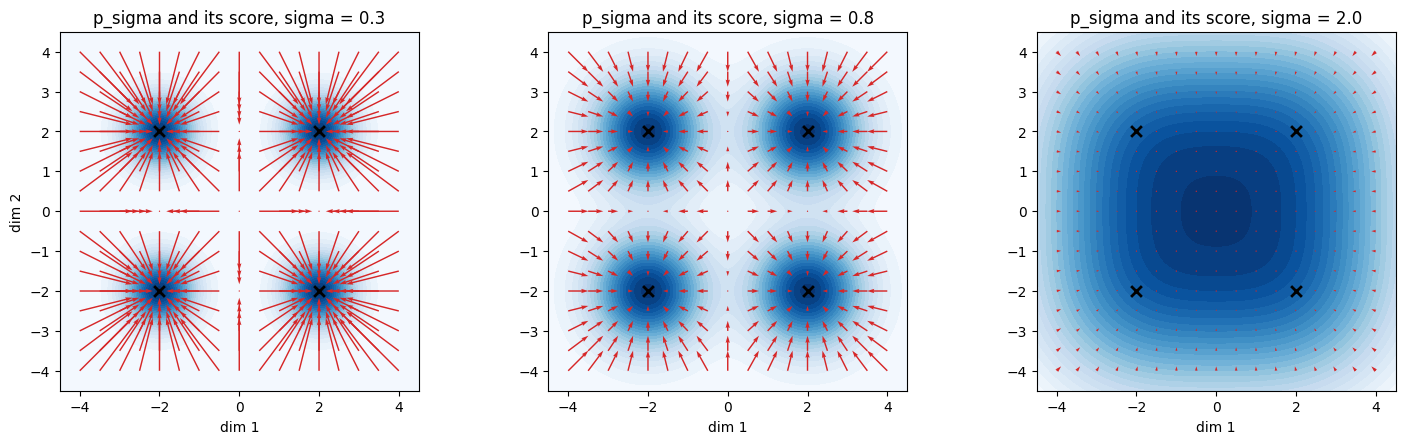

sigma が大きいほど分布が滑らかになり、スコア場も滑らかで遠くまで届く。
sigma = 2.0 では4つの峰が1つに融合している。
-> これが 194 の焼きなましで欲しかった「平坦にした分布の正しいスコア」。


In [4]:
# ============================================================
# 図: スコア場と、DSM が回帰しているもの
# ============================================================

gx = torch.linspace(-4, 4, 17)
GX, GY = torch.meshgrid(gx, gx, indexing="ij")
Q = torch.stack([GX.reshape(-1), GY.reshape(-1)], -1)
gx_f = torch.linspace(-4.5, 4.5, 160)
FX, FY = torch.meshgrid(gx_f, gx_f, indexing="ij")
F = torch.stack([FX.reshape(-1), FY.reshape(-1)], -1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, sigma in zip(axes, [0.3, 0.8, 2.0]):
    dens = log_p_sigma(F, sigma).exp().numpy().reshape(FX.shape)
    ax.contourf(FX.numpy(), FY.numpy(), dens, levels=25, cmap="Blues")
    s = score_sigma(Q, sigma)
    ax.quiver(Q[:, 0], Q[:, 1], s[:, 0], s[:, 1], color="tab:red",
              scale=40, width=0.004)
    ax.scatter(MUS[:, 0], MUS[:, 1], s=60, marker="x", color="k", lw=2)
    ax.set_aspect("equal")
    ax.set_xlabel("dim 1")
    ax.set_title(f"p_sigma and its score, sigma = {sigma}")
    ax.grid(False)
axes[0].set_ylabel("dim 2")

plt.tight_layout()
plt.show()

print("sigma が大きいほど分布が滑らかになり、スコア場も滑らかで遠くまで届く。")
print("sigma = 2.0 では4つの峰が1つに融合している。")
print("-> これが 194 の焼きなましで欲しかった「平坦にした分布の正しいスコア」。")

### 読み取れること

恒等式は 3つの $\sigma$ すべてで **float32 の精度まで一致**しました
（最大差 $3.9\times10^{-6}$ / $2.4\times10^{-7}$ / $4.7\times10^{-8}$。
$\sigma$ が小さいほど差が大きいのは、割る $\sigma^2$ が小さく桁落ちするためです）。

図が示す構造が本章の鍵です。

| $\sigma$ | 分布の形 | スコア場 |
|---|---|---|
| 0.3 | 4つの峰が明確に分離 | 各峰の近傍だけで強い。峰の間はほぼ 0 |
| 0.8 | 峰が広がり裾が重なる | 中間領域にも向きがある |
| 2.0 | **4つの峰が1つに融合** | 全域で原点方向を向く滑らかな場 |

194 の焼きなましで欲しかったのは、まさに $\sigma = 2.0$ の**正しいスコア**です。
194 では $p_0$ のスコアを $1/T$ 倍して代用していましたが、
それは「平坦にした分布のスコア」ではありません。
**各ノイズレベルの正しいスコアを学習しておけば代用が不要になります。**
第6節でその差を測ります。

<a id="noise-is-score"></a>
## 4. ノイズ予測はスコア学習である

ここが本章の核心です。37-45 で実装した拡散モデルを思い出します。

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1 - \bar\alpha_t}\,\epsilon,
\qquad \epsilon \sim \mathcal{N}(0, I)$$

そして損失は「足したノイズを当てる」ものでした。

$$\mathcal{L}_{\text{DDPM}} = \mathbb{E}\big\|\epsilon - \epsilon_\theta(x_t, t)\big\|^2$$

### 等価性の導出

$x_t$ は $x_0$ を $\sqrt{\bar\alpha_t}$ 倍して $\sqrt{1-\bar\alpha_t}$ のノイズを足したものです。
変数を $\sqrt{\bar\alpha_t}$ で割ると

$$\frac{x_t}{\sqrt{\bar\alpha_t}} = x_0
+ \underbrace{\frac{\sqrt{1-\bar\alpha_t}}{\sqrt{\bar\alpha_t}}}_{=: \sigma_t}\,\epsilon$$

つまり **DDPM の前向き過程は、スケール変換を除けば $\sigma_t$ のノイズを足すのと同じ**です。
第3節の恒等式を $x_t$ の座標で書き直すと

$$\nabla_{x_t} \log p_t(x_t)
= -\,\frac{\mathbb{E}[\epsilon \mid x_t]}{\sqrt{1 - \bar\alpha_t}}$$

$\epsilon_\theta$ は $\mathbb{E}[\epsilon \mid x_t]$ を学習しているので（二乗誤差の最適解は条件付き平均 —
**47 章の MDN で導出したあの性質**です）、

$$\boxed{\;\epsilon_\theta(x_t, t) = -\sqrt{1-\bar\alpha_t}\;\;
s_\theta(x_t, t), \qquad s_\theta \approx \nabla_{x_t}\log p_t\;}$$

**ノイズ予測ネットワークはスコアを学習していた。** 係数まで決まっています。

数値で確かめます。解析的に分かる GMM で、
$-\sqrt{1-\bar\alpha}\,\nabla_{x_t}\log p_t(x_t)$ と $\mathbb{E}[\epsilon \mid x_t]$ を
直接比べます。

In [5]:
# ============================================================
# ノイズ予測 = スコア（係数込み）の数値検証
# ============================================================

def score_of_pt(x_t, abar):
    # p_t は p_0 を sqrt(abar) 倍して sqrt(1-abar) のノイズを足した分布。
    # y = x_t/sqrt(abar) とおくと y ~ p_{sigma_eff}、sigma_eff = sqrt(1-abar)/sqrt(abar)
    # 変数変換より ∇_{x_t} log p_t(x_t) = (1/sqrt(abar)) ∇_y log p_{sigma_eff}(y)
    sigma_eff = math.sqrt(1 - abar) / math.sqrt(abar)
    y = x_t / math.sqrt(abar)
    return score_sigma(y, sigma_eff) / math.sqrt(abar)

def expected_eps_given_xt(x_t, abar):
    # E[eps | x_t] を直接: eps = (x_t - sqrt(abar) x_0)/sqrt(1-abar) の事後平均
    sigma_eff = math.sqrt(1 - abar) / math.sqrt(abar)
    y = x_t / math.sqrt(abar)
    x0_mean = posterior_mean(y, sigma_eff)              # E[x_0 | x_t]
    return (x_t - math.sqrt(abar) * x0_mean) / math.sqrt(1 - abar)

equiv_rows = []
print("abar      sigma_eff   max | -sqrt(1-abar)*score  -  E[eps|x_t] |")
print("-" * 68)
for abar in [0.99, 0.9, 0.5, 0.1, 0.01]:
    from_score = -math.sqrt(1 - abar) * score_of_pt(x_probe, abar)
    direct = expected_eps_given_xt(x_probe, abar)
    err = float((from_score - direct).abs().max())
    sigma_eff = math.sqrt(1 - abar) / math.sqrt(abar)
    equiv_rows.append((abar, sigma_eff, err))
    print(f"{abar:5.2f}     {sigma_eff:8.4f}    {err:.2e}")

print()
print("-> すべての abar で float32 の精度まで一致。")
print("   DDPM のノイズ予測ネットワークは、係数 -sqrt(1-abar) を掛ければスコアそのもの。")
print()
print("具体的な値で確認（abar = 0.5、x~ = [1.9, 2.1]）:")
abar = 0.5
i = 1
print(f"  スコア  ∇log p_t(x_t)            = {score_of_pt(x_probe, abar)[i].numpy().round(5)}")
print(f"  -sqrt(1-abar) * スコア            = {(-math.sqrt(1-abar)*score_of_pt(x_probe, abar))[i].numpy().round(5)}")
print(f"  E[eps|x_t]（ノイズ予測の最適解） = {expected_eps_given_xt(x_probe, abar)[i].numpy().round(5)}")

abar      sigma_eff   max | -sqrt(1-abar)*score  -  E[eps|x_t] |
--------------------------------------------------------------------
 0.99       0.1005    3.04e-06
 0.90       0.3333    4.17e-07
 0.50       1.0000    2.38e-07
 0.10       3.0000    2.38e-07
 0.01       9.9499    2.38e-07

-> すべての abar で float32 の精度まで一致。
   DDPM のノイズ予測ネットワークは、係数 -sqrt(1-abar) を掛ければスコアそのもの。

具体的な値で確認（abar = 0.5、x~ = [1.9, 2.1]）:
  スコア  ∇log p_t(x_t)            = [-0.77809 -1.0976 ]
  -sqrt(1-abar) * スコア            = [0.55019 0.77612]
  E[eps|x_t]（ノイズ予測の最適解） = [0.55019 0.77612]


### 読み取れること — 既に書いたコードの意味が変わる

| $\bar\alpha$ | $\sigma_{\text{eff}}$ | $\|-\sqrt{1-\bar\alpha}\,s - \mathbb{E}[\epsilon\mid x_t]\|_\infty$ |
|---|---|---|
| 0.99 | 0.1005 | $3.0\times10^{-6}$ |
| 0.90 | 0.3333 | $4.2\times10^{-7}$ |
| 0.50 | 1.0000 | $2.4\times10^{-7}$ |
| 0.10 | 3.0000 | $2.4\times10^{-7}$ |
| 0.01 | 9.9499 | $2.4\times10^{-7}$ |

**完全に一致します。** したがって次が確定します。

> **42 章で実装したノイズ予測 U-Net $\epsilon_\theta(x_t, t)$ は、
> 各ノイズレベル $t$ におけるスコア $\nabla_{x_t}\log p_t(x_t)$ を
> $-\sqrt{1-\bar\alpha_t}$ 倍したものを学習していた。**

3つの系列が1つに繋がります。

| 文脈 | 学んでいるもの | 本章で分かったこと |
|---|---|---|
| 193-194 EBM | $-\nabla_x E = \nabla_x \log p$ | スコアが本質。$E$ は要らない |
| 本章 DSM | $\nabla_{\tilde x}\log p_\sigma$ | ノイズを当てる回帰で学べる |
| 37-45 拡散 | $\epsilon_\theta(x_t,t)$ | **= スコア × $(-\sqrt{1-\bar\alpha_t})$** |

そして 194 の焼きなましが拡散モデルの逆過程に見えたのは、
**同じものだったから**です。

> 📌 **「$E$ は要らない」の意味**: スコアだけ学べば、サンプリング（194 のランジュバン）も
> できます。エネルギー $E$ を明示的に持たないので**尤度は計算できません**が、
> サンプリングには不要です。
> 拡散モデルが「尤度が下界しか出ないのに品質が高い」のはこの選択の結果です。
> $E$ を捨てる代わりに、$E$ の勾配を**ノイズレベルごとに正確に**学んでいます。

<a id="train-ebm"></a>
## 5. DSM で EBM を学習する — Z も負のサンプルも要らない

スコアだけ学ぶなら $E$ は不要ですが、**$E$ をスコアの原始関数として持たせる**ことも
できます。$s_\theta = -\nabla_x E_\theta$ とパラメータ化して DSM で学習すれば、

- **$Z$ は要らない**（スコアに $Z$ が現れない）
- **負のサンプルも要らない**（ランジュバンを一切回さない）
- しかも**エネルギー $E_\theta$ が手に入る**

193 の最尤学習は $Z$ が必要で、194 の CD はサンプリングが必要でした。
**DSM はどちらも要りません。**

### 評価の設計

193・194 と同じ 2次元の目標分布を使い、評価だけ格子で $\log Z$ を厳密に計算します。
これで**同じ尺度で3つの学習法を比べられます**。

| 学習法 | $Z$ | サンプリング | 本章までの実測 |
|---|---|---|---|
| 厳密最尤（193） | **必要** | 不要 | 2.8309（+0.0034） |
| CD（194） | 不要 | **必要** | CD-50 で 2.8606、CD-1 は崩壊 |
| **DSM（本節）** | **不要** | **不要** | ？ |

### $\sigma$ の選択

DSM は $p_\sigma$ のスコアを学ぶので、学習される分布は**$\sigma$ だけぼけた**ものです。

| $\sigma$ | バイアス | 分散 |
|---|---|---|
| 小さい | 小さい（$p_0$ に近い） | **大きい**（回帰の目標 $(x-\tilde x)/\sigma^2$ が $1/\sigma^2$ で暴れる） |
| 大きい | **大きい**（ぼけた分布を学ぶ） | 小さい |

トレードオフがあるので、$\sigma$ を振って測ります。

In [6]:
# ============================================================
# 評価用の設定（193・194 と完全に同じ目標分布・格子）
# ============================================================

MUS4 = np.array([[-2.0, -2.0], [2.0, 2.0], [-2.0, 2.0], [2.0, -2.0]])
SD4 = 0.5

def sample_gmm4(n, seed=0):
    r = np.random.default_rng(seed)
    k = r.integers(0, 4, n)
    return (MUS4[k] + r.standard_normal((n, 2)) * SD4).astype(np.float32)

def logsumexp_np(a, axis):
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def gmm4_logpdf(x):
    comps = [-0.5 * ((x - m) ** 2).sum(-1) / SD4**2 - np.log(2 * np.pi * SD4**2)
             for m in MUS4]
    return logsumexp_np(np.stack(comps, -1), axis=-1) + np.log(0.25)

X4_train = sample_gmm4(8000, seed=0)
X4_test = sample_gmm4(4000, seed=1)
NLL_LB = float(-gmm4_logpdf(X4_test).mean())

K4 = 128
g4 = torch.linspace(-5, 5, K4)
CELL4 = float(10.0 / (K4 - 1)) ** 2
G4X, G4Y = torch.meshgrid(g4, g4, indexing="ij")
GRID4 = torch.stack([G4X.reshape(-1), G4Y.reshape(-1)], -1)

NLL_EXACT_ML = 2.8309      # 193 の実測
NLL_CD50 = 2.8606          # 194 の実測
NLL_CD10 = 3.3307          # 194 の実測

print(f"下限 {NLL_LB:.4f}")
print(f"参照: 193 厳密最尤 {NLL_EXACT_ML:.4f} / 194 CD-50 {NLL_CD50:.4f} / "
      f"194 CD-10 {NLL_CD10:.4f} / 194 CD-1 4.4e9（崩壊）")


class EnergyNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


def log_partition4(E_net):
    return torch.logsumexp(-E_net(GRID4), 0) + math.log(CELL4)

下限 2.8275
参照: 193 厳密最尤 2.8309 / 194 CD-50 2.8606 / 194 CD-10 3.3307 / 194 CD-1 4.4e9（崩壊）


In [7]:
# ============================================================
# DSM でエネルギー関数を学習する（Z なし・サンプリングなし）
# ============================================================

def train_energy_dsm(sigma, steps=3000, batch=512, lr=2e-3, seed=1):
    torch.manual_seed(seed)
    E_net = EnergyNet()
    opt = torch.optim.Adam(E_net.parameters(), lr=lr)
    X = torch.tensor(X4_train)
    t0 = time.time()
    for _ in range(steps):
        x = X[torch.randint(0, len(X), (batch,))]
        eps = torch.randn_like(x)
        x_tilde = (x + sigma * eps).requires_grad_(True)
        # score = -grad E。create_graph=True で2階微分を通す
        score = -torch.autograd.grad(E_net(x_tilde).sum(), x_tilde,
                                     create_graph=True)[0]
        loss = ((sigma * score + eps) ** 2).sum(-1).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
    with torch.no_grad():
        test_nll = float(E_net(torch.tensor(X4_test)).mean() + log_partition4(E_net))
        dens = torch.exp(-E_net(GRID4) - log_partition4(E_net))
    return {"nll": test_nll, "time": time.time() - t0,
            "dens": dens.numpy().reshape(K4, K4), "net": E_net}

dsm_rows = []
for sigma in [0.05, 0.1, 0.2, 0.4]:
    res = train_energy_dsm(sigma)
    dsm_rows.append((sigma, res))
    print(f"sigma = {sigma:4.2f}: test NLL {res['nll']:8.4f}   "
          f"（下限まで {res['nll'] - NLL_LB:+.4f}）   {res['time']:.0f}s")

best_sigma, best_res = min(dsm_rows, key=lambda r: r[1]["nll"])
print()
print(f"最良は sigma = {best_sigma}: {best_res['nll']:.4f}（下限まで "
      f"{best_res['nll'] - NLL_LB:+.4f}）")
print()
print("同じ目標分布・同じ評価での比較:")
print(f"  到達可能な下限                          {NLL_LB:.4f}")
print(f"  193 厳密最尤（Z が必要・d=2 限定）        {NLL_EXACT_ML:.4f}  (+{NLL_EXACT_ML-NLL_LB:.4f})")
print(f"  194 CD-50（サンプリング 46s）             {NLL_CD50:.4f}  (+{NLL_CD50-NLL_LB:.4f})")
print(f"  195 DSM sigma={best_sigma}（Z もサンプリングも不要・{best_res['time']:.0f}s）"
      f"  {best_res['nll']:.4f}  (+{best_res['nll']-NLL_LB:.4f})")
print(f"  194 CD-10（サンプリング 11s）             {NLL_CD10:.4f}  (+{NLL_CD10-NLL_LB:.4f})")
print(f"  194 CD-1                                4.4e9（崩壊）")

sigma = 0.05: test NLL   2.9729   （下限まで +0.1454）   7s


sigma = 0.10: test NLL   2.9199   （下限まで +0.0924）   7s


sigma = 0.20: test NLL   2.8772   （下限まで +0.0496）   7s


sigma = 0.40: test NLL   2.9281   （下限まで +0.1006）   7s

最良は sigma = 0.2: 2.8772（下限まで +0.0496）

同じ目標分布・同じ評価での比較:
  到達可能な下限                          2.8275
  193 厳密最尤（Z が必要・d=2 限定）        2.8309  (+0.0034)
  194 CD-50（サンプリング 46s）             2.8606  (+0.0331)
  195 DSM sigma=0.2（Z もサンプリングも不要・7s）  2.8772  (+0.0496)
  194 CD-10（サンプリング 11s）             3.3307  (+0.5032)
  194 CD-1                                4.4e9（崩壊）


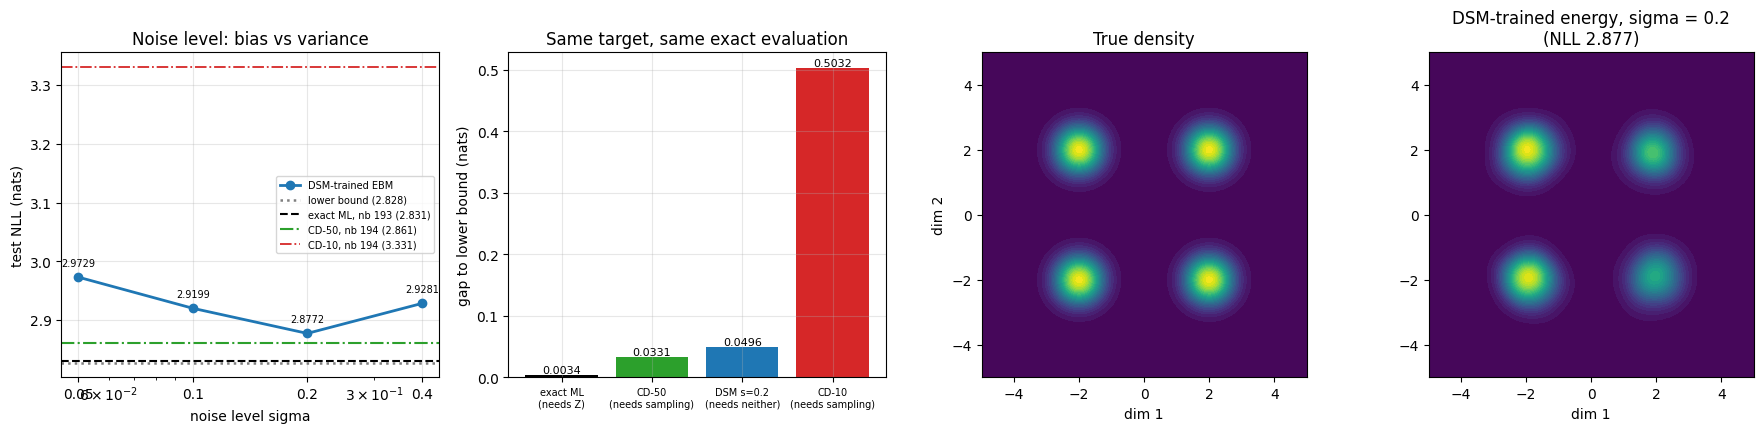

In [8]:
# ============================================================
# 図: sigma のトレードオフと学習された密度
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))

sgs = [r[0] for r in dsm_rows]
nlls = [r[1]["nll"] for r in dsm_rows]
axes[0].semilogx(sgs, nlls, "o-", lw=2, color="tab:blue", label="DSM-trained EBM")
axes[0].axhline(NLL_LB, color="tab:gray", ls=":", lw=1.8,
                label=f"lower bound ({NLL_LB:.3f})")
axes[0].axhline(NLL_EXACT_ML, color="k", ls="--", lw=1.5,
                label=f"exact ML, nb 193 ({NLL_EXACT_ML:.3f})")
axes[0].axhline(NLL_CD50, color="tab:green", ls="-.", lw=1.5,
                label=f"CD-50, nb 194 ({NLL_CD50:.3f})")
axes[0].axhline(NLL_CD10, color="tab:red", ls="-.", lw=1.3,
                label=f"CD-10, nb 194 ({NLL_CD10:.3f})")
axes[0].set_xlabel("noise level sigma")
axes[0].set_ylabel("test NLL (nats)")
axes[0].set_title("Noise level: bias vs variance")
axes[0].set_xticks(sgs)
axes[0].set_xticklabels([str(s) for s in sgs])
axes[0].legend(fontsize=7)
for s, v in zip(sgs, nlls):
    axes[0].annotate(f"{v:.4f}", (s, v), textcoords="offset points",
                     xytext=(0, 8), fontsize=7, ha="center")

methods = ["exact ML\n(needs Z)", "CD-50\n(needs sampling)",
           f"DSM s={best_sigma}\n(needs neither)", "CD-10\n(needs sampling)"]
vals = [NLL_EXACT_ML - NLL_LB, NLL_CD50 - NLL_LB,
        best_res["nll"] - NLL_LB, NLL_CD10 - NLL_LB]
axes[1].bar(methods, vals, color=["k", "tab:green", "tab:blue", "tab:red"])
axes[1].set_ylabel("gap to lower bound (nats)")
axes[1].set_title("Same target, same exact evaluation")
for i, v in enumerate(vals):
    axes[1].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
axes[1].tick_params(axis="x", labelsize=7)

dens_true4 = np.exp(gmm4_logpdf(np.stack([G4X.numpy(), G4Y.numpy()], -1)))
axes[2].contourf(G4X.numpy(), G4Y.numpy(), dens_true4, levels=30, cmap="viridis")
axes[2].set_aspect("equal")
axes[2].set_title("True density")
axes[2].set_xlabel("dim 1")
axes[2].set_ylabel("dim 2")
axes[2].grid(False)

axes[3].contourf(G4X.numpy(), G4Y.numpy(), best_res["dens"], levels=30, cmap="viridis")
axes[3].set_aspect("equal")
axes[3].set_title(f"DSM-trained energy, sigma = {best_sigma}\n(NLL {best_res['nll']:.3f})")
axes[3].set_xlabel("dim 1")
axes[3].grid(False)

plt.tight_layout()
plt.show()

### 読み取れること — $\sigma$ の U字と、3つの学習法の順位

| $\sigma$ | test NLL | 下限までの差 |
|---|---|---|
| 0.05 | 2.9729 | +0.1454 |
| 0.1 | 2.9199 | +0.0924 |
| **0.2** | **2.8772** | **+0.0496** |
| 0.4 | 2.9281 | +0.1006 |

**U字になりました。** 予想どおりのバイアスと分散のトレードオフです。

- $\sigma = 0.05$: 回帰の目標 $(x - \tilde x)/\sigma^2 = -\epsilon/\sigma$ は
  標準偏差 $1/0.05 = 20$ で暴れます。推定が不安定でバイアス以上に損をします。
- $\sigma = 0.4$: データの $\sigma_0 = 0.5$ に近く、分布が実際にぼけます。

同じ目標分布・同じ厳密評価での順位はこうなりました。

| 学習法 | 下限までの差 | $Z$ | サンプリング | 時間 |
|---|---|---|---|---|
| 厳密最尤（193） | **+0.0034** | 必要 | 不要 | 17s |
| CD-50（194） | +0.0331 | 不要 | 必要 | 46s |
| **DSM $\sigma=0.2$（本節）** | **+0.0496** | **不要** | **不要** | **7s** |
| CD-10（194） | +0.5032 | 不要 | 必要 | 11s |
| CD-1（194） | 崩壊（$4.4\times10^9$） | 不要 | 必要 | 3s |

**DSM は CD-50 にわずかに負けますが、6.5 倍速く、そして崩壊しません。**
CD は $k$ を十分大きくしないと崩壊しましたが（CD-1 で $4.4\times10^9$）、
DSM は**どの $\sigma$ でも安定**でした。最悪の $\sigma = 0.05$ でも +0.1454 です。

これが重要な理由は、**崩壊のリスクが構造的に無い**ことです。
DSM の損失 $\|\sigma s_\theta + \epsilon\|^2$ は**下に有界（0 以上）**です。
194 の CD の損失 $E(x_{\text{data}}) - E(x_{\text{neg}})$ は下に有界ではなく、
だから発散できました。目的関数の形が安定性を決めています。

> 💡 **なぜ厳密最尤に負けるのか**: DSM が学ぶのは $p_\sigma$（ぼけた分布）の
> スコアです。$\sigma \to 0$ の極限で $p_0$ に一致しますが、
> そこでは分散が発散します。**原理的なバイアスが残る**のが DSM の代償です。
> 一方で $Z$ もサンプリングも要らないので、**高次元で唯一実行可能**な選択肢になります。

<a id="annealed"></a>
## 6. ノイズレベル別スコア + 焼きなまし

194 の焼きなましの弱点は「$p_0$ のスコアを $1/T$ 倍して代用していた」ことでした。
第3節で見たとおり、それは**平坦にした分布のスコアではありません**。

本節では **ノイズレベル $\sigma$ を条件に取るスコアネットワーク** $s_\theta(x, \sigma)$ を
DSM で学習し、$\sigma$ を大きい方から小さい方へ下げながらランジュバンを回します
（Song & Ermon 2019 の annealed Langevin dynamics）。

$$\text{for } \sigma_1 > \sigma_2 > \cdots > \sigma_L:
\quad x \leftarrow x + \frac{\alpha_i}{2} s_\theta(x, \sigma_i)
+ \sqrt{\alpha_i}\,\eta, \qquad \alpha_i = \epsilon_0 \frac{\sigma_i^2}{\sigma_L^2}$$

194 と**同じ目標分布**（12 シグマ離れた 4 峰）、**同じ非対称な初期値**
（全チェーンがモード0から出発）で比べます。**同一の計算予算で**比較するのが要点です。

In [9]:
# ============================================================
# 194 と同じ目標分布（12シグマ離れた4峰）
# ============================================================

MODES = torch.tensor([[-3.0, -3.0], [3.0, 3.0], [-3.0, 3.0], [3.0, -3.0]])
MODE_SD = 0.5

def sample_far(n, seed=0):
    r = np.random.default_rng(seed)
    k = r.integers(0, 4, n)
    return (MODES.numpy()[k] + r.standard_normal((n, 2)) * MODE_SD).astype(np.float32)

X_far = torch.tensor(sample_far(20000, seed=0))

def score_far_sigma(x, sigma):
    # 解析スコア（学習結果の検算用）
    v = MODE_SD**2 + sigma**2
    d2 = ((x[:, None, :] - MODES[None]) ** 2).sum(-1)
    r = torch.softmax(-0.5 * d2 / v - math.log(2 * math.pi * v), -1)
    return ((MODES[None] - x[:, None, :]) / v * r[..., None]).sum(1)

def nearest_mode(x):
    return ((x[:, None, :] - MODES[None]) ** 2).sum(-1).argmin(-1)

def mixing_report(x, visits, n):
    n_visited = torch.tensor([torch.unique(visits[:, i]).numel()
                              for i in range(n)]).float()
    occ = torch.bincount(nearest_mode(x), minlength=4).float() / n
    return float(n_visited.mean()), occ, float((occ - 0.25).abs().max())

SIGMAS = torch.exp(torch.linspace(math.log(5.0), math.log(0.05), 10))
print("ノイズレベルのはしご:", SIGMAS.numpy().round(3))
print(f"最大 {float(SIGMAS[0]):.1f} はモード間隔 "
      f"{float((MODES[0]-MODES[1]).norm()):.1f} と同程度 -> 峰が融合する")
print(f"最小 {float(SIGMAS[-1]):.2f} はデータの標準偏差 {MODE_SD} より小さい -> 元の分布に近い")

ノイズレベルのはしご: [5.    2.997 1.797 1.077 0.646 0.387 0.232 0.139 0.083 0.05 ]
最大 5.0 はモード間隔 8.5 と同程度 -> 峰が融合する
最小 0.05 はデータの標準偏差 0.5 より小さい -> 元の分布に近い


In [10]:
# ============================================================
# ノイズレベルを条件に取るスコアネットワークを DSM で学習
# ============================================================

class ConditionalScoreNet(nn.Module):
    # s_theta(x, sigma)。スコアは 1/sigma のスケールを持つので出力を sigma で割る
    def __init__(self, hidden=192):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, sigma):
        log_sigma = torch.log(sigma).reshape(-1, 1)
        out = self.net(torch.cat([x, log_sigma], -1))
        return out / sigma.reshape(-1, 1)


torch.manual_seed(2)
score_net = ConditionalScoreNet()
opt = torch.optim.Adam(score_net.parameters(), lr=2e-3)

t0 = time.time()
loss_hist = []
for step in range(6000):
    x = X_far[torch.randint(0, len(X_far), (512,))]
    si = SIGMAS[torch.randint(0, len(SIGMAS), (512,))]
    eps = torch.randn_like(x)
    x_tilde = x + si[:, None] * eps
    # sigma 重み付き DSM: || sigma * s + eps ||^2。全ノイズレベルで損失が同程度になる
    loss = ((si[:, None] * score_net(x_tilde, si) + eps) ** 2).sum(-1).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
    loss_hist.append(float(loss.detach()))

print(f"学習 {time.time() - t0:.0f}s   最終損失 {loss_hist[-1]:.4f}")
print()

# 学習したスコアを解析スコアと比べる
print("学習スコア vs 解析スコア（相対誤差の中央値）:")
score_err_rows = []
with torch.no_grad():
    for sg in SIGMAS:
        xs = X_far[:2000] + sg * torch.randn(2000, 2)
        pred = score_net(xs, sg.repeat(2000))
        true = score_far_sigma(xs, float(sg))
        rel = float(((pred - true).norm(dim=-1)
                     / (true.norm(dim=-1) + 1e-6)).median())
        score_err_rows.append((float(sg), rel))
        print(f"  sigma = {float(sg):6.3f}: {rel:.4f}")
print()
print("-> 小さい sigma ほど難しい。第5節の U 字（小さい sigma で分散が暴れる）と整合する。")

学習 7s   最終損失 1.2294

学習スコア vs 解析スコア（相対誤差の中央値）:
  sigma =  5.000: 0.0850
  sigma =  2.997: 0.1268
  sigma =  1.797: 0.1211
  sigma =  1.077: 0.1130
  sigma =  0.646: 0.1126
  sigma =  0.387: 0.1073
  sigma =  0.232: 0.1682
  sigma =  0.139: 0.2982
  sigma =  0.083: 0.4901
  sigma =  0.050: 0.7708

-> 小さい sigma ほど難しい。第5節の U 字（小さい sigma で分散が暴れる）と整合する。


In [11]:
# ============================================================
# 焼きなましランジュバン: 194 方式（代用スコア）vs 195 方式（学習スコア）
# ============================================================

N_CHAIN = 2000
torch.manual_seed(5)
x0_one_mode = MODES[0] + torch.randn(N_CHAIN, 2) * 0.3    # 194 と同じ非対称な初期値

def score_p0_analytic(x):
    # 194 で使っていた「p_0 のスコア」
    d2 = ((x[:, None, :] - MODES[None]) ** 2).sum(-1)
    r = torch.softmax(-0.5 * d2 / MODE_SD**2 - math.log(2 * math.pi * MODE_SD**2), -1)
    return ((MODES[None] - x[:, None, :]) / MODE_SD**2 * r[..., None]).sum(1)

def anneal_194(steps, eps=0.05, seed=2):
    # 194 方式: p_0 のスコアを 1/T 倍する温度焼きなまし
    temps = torch.exp(torch.linspace(math.log(40.0), math.log(1.0), steps))
    gen = torch.Generator().manual_seed(seed)
    x = x0_one_mode.clone()
    visits = []
    for t in range(steps):
        T = float(temps[t])
        x = (x + 0.5 * eps * score_p0_analytic(x) / T
             + math.sqrt(eps) * torch.randn(N_CHAIN, 2, generator=gen))
        if t % 10 == 0:
            visits.append(nearest_mode(x))
    return x, torch.stack(visits)

@torch.no_grad()
def anneal_195(steps_per_level, eps0=2e-4, seed=3):
    # 195 方式: ノイズレベルごとに学習した正しいスコアを使う
    gen = torch.Generator().manual_seed(seed)
    x = x0_one_mode.clone()
    visits = []
    for sg in SIGMAS:
        alpha = eps0 * (sg / SIGMAS[-1]) ** 2
        for _ in range(steps_per_level):
            x = (x + 0.5 * alpha * score_net(x, sg.repeat(N_CHAIN))
                 + math.sqrt(alpha) * torch.randn(N_CHAIN, 2, generator=gen))
            if len(visits) % 1 == 0:
                visits.append(nearest_mode(x))
    return x, torch.stack(visits)

print("194 方式（p_0 のスコアを 1/T 倍）:")
rows_194 = []
final_194 = {}
for steps in [500, 1000, 2000, 6000]:
    x, vis = anneal_194(steps)
    visited, occ, maxdev = mixing_report(x, vis, N_CHAIN)
    rows_194.append((steps, visited, occ.numpy(), maxdev))
    final_194[steps] = x
    print(f"  {steps:5d} step: 訪問モード数 {visited:.2f}/4  "
          f"占有率 {occ.numpy().round(3)}  最大偏差 {maxdev:.3f}")

print()
print("195 方式（ノイズレベル別に学習したスコア）:")
rows_195 = []
final_195 = {}
for per_level in [20, 50, 100]:
    x, vis = anneal_195(per_level)
    total = per_level * len(SIGMAS)
    visited, occ, maxdev = mixing_report(x, vis, N_CHAIN)
    rows_195.append((total, visited, occ.numpy(), maxdev))
    final_195[total] = x
    print(f"  {total:5d} step ({len(SIGMAS)} レベル x {per_level}): "
          f"訪問モード数 {visited:.2f}/4  占有率 {occ.numpy().round(3)}  "
          f"最大偏差 {maxdev:.3f}")

print()
print("同一予算での比較:")
for steps in [500, 1000]:
    r4 = [r for r in rows_194 if r[0] == steps][0]
    r5 = [r for r in rows_195 if r[0] == steps][0]
    print(f"  {steps} step: 194 方式 最大偏差 {r4[3]:.3f} (訪問 {r4[1]:.2f}) / "
          f"195 方式 最大偏差 {r5[3]:.3f} (訪問 {r5[1]:.2f}) "
          f"-> {r4[3]/r5[3]:.0f} 倍の改善")

194 方式（p_0 のスコアを 1/T 倍）:
    500 step: 訪問モード数 1.51/4  占有率 [0.698 0.025 0.133 0.144]  最大偏差 0.448


   1000 step: 訪問モード数 1.91/4  占有率 [0.535 0.071 0.201 0.193]  最大偏差 0.285


   2000 step: 訪問モード数 2.50/4  占有率 [0.369 0.148 0.238 0.244]  最大偏差 0.119


   6000 step: 訪問モード数 3.54/4  占有率 [0.269 0.242 0.237 0.252]  最大偏差 0.019

195 方式（ノイズレベル別に学習したスコア）:


    200 step (10 レベル x 20): 訪問モード数 2.80/4  占有率 [0.36  0.168 0.23  0.244]  最大偏差 0.109


    500 step (10 レベル x 50): 訪問モード数 3.54/4  占有率 [0.294 0.214 0.222 0.27 ]  最大偏差 0.044


   1000 step (10 レベル x 100): 訪問モード数 3.90/4  占有率 [0.26  0.226 0.236 0.278]  最大偏差 0.028

同一予算での比較:
  500 step: 194 方式 最大偏差 0.448 (訪問 1.51) / 195 方式 最大偏差 0.044 (訪問 3.54) -> 10 倍の改善
  1000 step: 194 方式 最大偏差 0.285 (訪問 1.91) / 195 方式 最大偏差 0.028 (訪問 3.90) -> 10 倍の改善


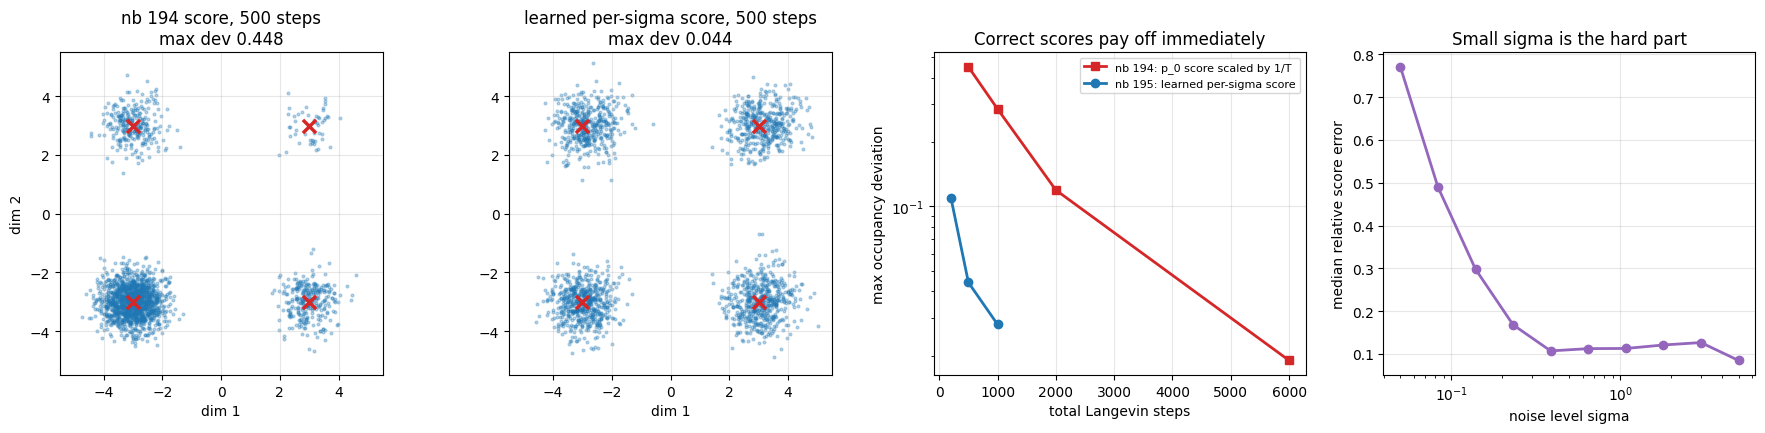

In [12]:
# ============================================================
# 図: 学習したスコアによる焼きなましの効果
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))

def scatter_modes(ax, x, title):
    xn = x.numpy()
    ax.scatter(xn[:, 0], xn[:, 1], s=4, alpha=0.3, color="tab:blue")
    ax.scatter(MODES[:, 0], MODES[:, 1], s=90, marker="x", color="tab:red", lw=2.5)
    ax.set_xlim(-5.5, 5.5)
    ax.set_ylim(-5.5, 5.5)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("dim 1")

r4_500 = [r for r in rows_194 if r[0] == 500][0]
r5_500 = [r for r in rows_195 if r[0] == 500][0]
scatter_modes(axes[0], final_194[500],
              f"nb 194 score, 500 steps\nmax dev {r4_500[3]:.3f}")
axes[0].set_ylabel("dim 2")
scatter_modes(axes[1], final_195[500],
              f"learned per-sigma score, 500 steps\nmax dev {r5_500[3]:.3f}")

axes[2].semilogy([r[0] for r in rows_194], [r[3] for r in rows_194], "s-", lw=2,
                 color="tab:red", label="nb 194: p_0 score scaled by 1/T")
axes[2].semilogy([r[0] for r in rows_195], [r[3] for r in rows_195], "o-", lw=2,
                 color="tab:blue", label="nb 195: learned per-sigma score")
axes[2].set_xlabel("total Langevin steps")
axes[2].set_ylabel("max occupancy deviation")
axes[2].set_title("Correct scores pay off immediately")
axes[2].legend(fontsize=8)

axes[3].semilogx([r[0] for r in score_err_rows], [r[1] for r in score_err_rows],
                 "o-", lw=2, color="tab:purple")
axes[3].set_xlabel("noise level sigma")
axes[3].set_ylabel("median relative score error")
axes[3].set_title("Small sigma is the hard part")

plt.tight_layout()
plt.show()

### 読み取れること — 194 の困難は「正しいスコア」で消える

| 総ステップ数 | 194 方式（代用スコア） | 195 方式（学習スコア） |
|---|---|---|
| 200 | — | 訪問 2.80 / 最大偏差 0.109 |
| 500 | 訪問 1.51 / 最大偏差 **0.448** | 訪問 3.54 / 最大偏差 **0.044** |
| 1,000 | 訪問 1.91 / 最大偏差 0.285 | 訪問 3.90 / 最大偏差 0.028 |
| 2,000 | 訪問 2.50 / 最大偏差 0.119 | — |
| 6,000 | 訪問 3.54 / 最大偏差 0.019 | — |

**同じ 500 ステップで最大偏差が 0.448 対 0.044 — 10 倍の差**です。
そして 195 方式は **500 ステップで、194 方式が 6,000 ステップかけて到達した
訪問モード数 3.54 に並びます**（12 倍の効率）。

なぜこれほど違うのか。194 方式は温度 $T$ で割ったスコアを使っていました。
$\nabla \log p_0 / T$ は $p_0^{1/T}$ のスコアです。これは「山を低くした分布」ですが、
**山の位置は変わりません**。山の間の谷も浅くなるだけで、
谷の底から見た「どちらの山へ行くべきか」の情報は増えません。

対して $\nabla \log p_\sigma$ は**畳み込んだ分布**のスコアです。
$\sigma$ が大きいと第3節の図のように**峰が融合して1つの山になり**、
全域から中心方向への滑らかな勾配が得られます。
谷が「浅くなる」のではなく「**無くなる**」のが決定的な違いです。

学習スコアの精度は小さい $\sigma$ で悪化します
（$\sigma = 5.0$ で相対誤差 0.085、$\sigma = 0.387$ で 0.107、
$\sigma = 0.139$ で 0.298、$\sigma = 0.05$ で **0.771**）。
これは第5節の U 字と同じ理由で、**DSM の目標が $1/\sigma$ でスケールするため**です。
それでもサンプリングは成功します。小さい $\sigma$ の段階では
すでに正しい峰の近くにいるので、スコアの精度が多少悪くても結果に響きません。
**精度が必要なのは大きい $\sigma$（どの峰へ行くか決める段階）**です。

<a id="summary"></a>
## 7. 3系統の統合

### 本章で示した等価性

$$\underbrace{\epsilon_\theta(x_t, t)}_{\text{42 章のノイズ予測 U-Net}}
= -\sqrt{1-\bar\alpha_t}\;
\underbrace{s_\theta(x_t, t)}_{\text{スコア}}
= \sqrt{1-\bar\alpha_t}\;
\underbrace{\nabla_{x_t} E_\theta(x_t, t)}_{\text{193 のエネルギーの勾配}}$$

数値検証: 5つの $\bar\alpha$ すべてで $10^{-6}$〜$10^{-7}$ 台の一致（float32 の精度）。

### 3系統の関係

```
                        p(x) を表現したい
                               |
        +----------------------+----------------------+
        |                      |                      |
   可逆変換で作る          エネルギーで作る        スコアだけ学ぶ
   （フロー 190-191）      （EBM 193-194）        （拡散 37-45, 195）
        |                      |                      |
  尤度: 厳密              尤度: Z が不能          尤度: 下界のみ
  生成: 逆写像1回         生成: ランジュバン      生成: 焼きなまし
  制約: 可逆・次元保存     制約: なし              制約: なし
        |                      |                      |
        +------- 191: 2.6552 bits/dim (d=196) --------+
                               |
                    195: スコアで EBM と拡散が繋がる
```

### 同じ目標分布（2次元4峰 GMM、下限 2.8275）での全手法比較

| 手法 | test NLL | 差 | $Z$ | サンプリング | 時間 | 高次元で可能か |
|---|---|---|---|---|---|---|
| 厳密最尤 EBM（193） | 2.8309 | +0.0034 | **必要** | 不要 | 17s | **不可** |
| CD-50（194） | 2.8606 | +0.0331 | 不要 | **必要** | 46s | 可（高コスト） |
| **DSM で EBM（195）** | **2.8772** | **+0.0496** | **不要** | **不要** | **7s** | **可** |
| RealNVP（191） | 2.8779 | +0.0504 | 構造で回避 | 不要 | — | 可 |
| CD-10（194） | 3.3307 | +0.5032 | 不要 | 必要 | 11s | 可 |
| CD-1（194） | $4.4\times10^9$ | 崩壊 | 不要 | 必要 | 3s | — |

**DSM と RealNVP がほぼ同じ精度**（2.8772 対 2.8779）なのは興味深い一致です。
両者は全く違う方針（スコア回帰 vs 可逆変換）なのに、同じ規模のネットワークで
同じところに着地しました。

### 焼きなましの比較（12シグマ離れた4峰、非対称な初期値）

| 総ステップ | 194（$p_0^{1/T}$ のスコア） | 195（$p_\sigma$ の学習スコア） |
|---|---|---|
| 500 | 最大偏差 0.448 | **0.044** |
| 1,000 | 0.285 | **0.028** |
| 6,000 | 0.019 | — |

**同一予算で 10 倍、同じ品質に 12 倍速く到達（500 step で 194 の 6,000 step に並ぶ）。**
理由は「山を低くする（$p^{1/T}$）」のと「山を融合させる（$p_\sigma$）」の違いです。

### 37-45 を読み返すと何が変わるか

| 37-45 で書いたこと | 本章以降の読み方 |
|---|---|
| ノイズスケジュール $\bar\alpha_t$ | **スコアを学ぶノイズレベルのはしご**（195 第6節の `SIGMAS`） |
| ノイズ予測の損失 $\|\epsilon - \epsilon_\theta\|^2$ | **$\sigma$ 重み付きデノイジングスコアマッチング** |
| 逆拡散のサンプリング | **焼きなましランジュバン**（194 + 正しいスコア） |
| ELBO が下界でしかないこと | スコアだけ学んでエネルギーを持たない選択の代償 |
| 44 章の Classifier-Free Guidance | スコアの線形結合（$Z$ が消えるので足し算できる） |

**拡散モデルは EBM の問題を「エネルギーを捨てて、勾配をノイズレベルごとに
正確に学ぶ」ことで解いたもの**です。194 で測った困難
（$\epsilon$ の窓が狭い・混合しない・CD が崩壊する）は、すべて本章の構成で消えます。

### 残る問い（196 で総括）

| 問い | 本ユニットで分かったこと |
|---|---|
| 厳密尤度は要るか | フローだけが持つ。制約の代償を払っている |
| サンプル品質と尤度は一致するか | **しない**（191 第7節: bits/dim 2.6552 でも数字に見えない） |
| 最も表現力が高いのは | EBM（制約なし）。だが計算可能性で負ける |
| 実務でどれを選ぶか | **196 で三すくみとして整理する** |

<a id="quiz"></a>
## 8. 自己評価クイズ

### Q1: ノイズを足すとトレースが消える理由

**問題**: 明示的スコアマッチングには $\mathrm{tr}(\nabla_x s_\theta)$ が必要で、
$d = 512$ では DSM の 56 倍のコストでした。
ノイズを足すとこの項が消えるのは、数学的に何が起きているからですか。

<details>
<summary>答えを見る</summary>

**目標が「未知のスコア」から「既知のノイズ」に置き換わるからです。**

明示的 SM の困難は $\nabla_x \log p_{\text{data}}$ が未知なことでした。
部分積分で消す代わりにトレースが出てきます。

DSM では、ノイズを足した $\tilde x = x + \sigma\epsilon$ に対して

$$\nabla_{\tilde x} \log p_\sigma(\tilde x)
= \mathbb{E}\Big[\frac{x - \tilde x}{\sigma^2}\Big|\tilde x\Big]
= \mathbb{E}\Big[\frac{-\epsilon}{\sigma}\Big|\tilde x\Big]$$

右辺は**サンプリングで作れる量の条件付き期待値**です。
そして二乗誤差の最適解は条件付き平均（**47 章で導出**）なので、
$\|\sigma s_\theta(\tilde x) + \epsilon\|^2$ を最小化すれば
自動的に $\sigma s_\theta \to -\mathbb{E}[\epsilon|\tilde x]$ になります。

つまり**未知の量を回帰問題に変換した**のであって、トレースを速く計算したのではありません。
190 で「行列式を計算する代わりに三角にした」のと同じ、
**計算を避ける構造への変換**です。

代償は、学ぶのが $p_0$ ではなく $p_\sigma$（ぼけた分布）のスコアになることです。
第5節で測った U 字（$\sigma = 0.2$ で最良、+0.0496）がその代償の大きさです。
</details>

---

### Q2: $\epsilon_\theta$ とスコアの符号

**問題**: $\epsilon_\theta(x_t, t) = -\sqrt{1-\bar\alpha_t}\, s_\theta(x_t, t)$ の
**マイナス符号**を直感的に説明してください。

<details>
<summary>答えを見る</summary>

$\epsilon$ は「データから離れる方向に足されたノイズ」です。
スコアは「確率が高くなる方向」、つまり**データへ戻る方向**を指します。
両者は逆向きなのでマイナスが付きます。

式で見ると、$x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon$ より

$$\epsilon = \frac{x_t - \sqrt{\bar\alpha_t}\,x_0}{\sqrt{1-\bar\alpha_t}}$$

で、$\epsilon$ は $x_t$ が $x_0$ から**どれだけどちらにずれたか**です。
戻るにはこの逆向きに進めばよいので、スコア（戻る方向）は $-\epsilon$ の向きになります。

係数 $\sqrt{1-\bar\alpha_t}$ は単位合わせです。スコアは $\log$ 密度の勾配なので
長さの逆数の次元を持ち、$1/\sigma$ でスケールします。
$\epsilon$ は標準正規なので無次元です。その変換係数が $\sqrt{1-\bar\alpha_t}$ です。

本章の実測では 5 つの $\bar\alpha$ すべてで $10^{-7}$ 台の一致でした。
**符号も係数も偶然の近似ではなく厳密な等式**です。
</details>

---

### Q3: DSM が崩壊しない理由

**問題**: 194 の CD-1 は test NLL が $4.4\times10^9$ まで吹き飛びましたが、
DSM はどの $\sigma$ でも安定でした（最悪 +0.1454）。
この違いを目的関数の形から説明してください。

<details>
<summary>答えを見る</summary>

**損失が下に有界かどうかの違いです。**

CD の損失は

$$\mathcal{L}_{\text{CD}} = E_\theta(x_{\text{data}}) - E_\theta(x_{\text{neg}})$$

で、**下に有界ではありません**。$x_{\text{neg}}$ が届かない領域では
$E_\theta$ をいくらでも下げられるので $\mathcal{L} \to -\infty$ が可能です。

DSM の損失は

$$\mathcal{L}_{\text{DSM}} = \mathbb{E}\big\|\sigma s_\theta(\tilde x) + \epsilon\big\|^2 \ge 0$$

で、**二乗なので 0 以上**です。最小値は $\sigma s_\theta = -\mathbb{E}[\epsilon|\tilde x]$ で
達成され、それ以上下がりません。**発散する余地が構造的にありません。**

さらに DSM は**サンプリングを含まない**ので、
「サンプラーが弱い → 学習が壊れる → エネルギーが鋭くなる → サンプラーがさらに弱くなる」
という 194 の悪循環も起きません。

この安定性が、高次元で DSM（= 拡散モデル）が実用になり
CD が使われなくなった実際的な理由です。
</details>

---

### Q4: $p^{1/T}$ と $p_\sigma$ はどう違うのか

**問題**: 194 の温度焼きなましは $p^{1/T}$ を、本章の焼きなましは
$p_\sigma = p * \mathcal{N}(0,\sigma^2)$ を経由します。
同一予算で最大偏差が 0.448 対 0.044 と 10 倍違いました。
2つの「平坦化」の違いを説明してください。

<details>
<summary>答えを見る</summary>

**$p^{1/T}$ は山を低くするだけで、山の位置を動かしません。**

$p^{1/T} \propto e^{-E/T}$ なので、$E$ の極小・極大の**位置は $T$ に依存しません**。
谷が浅くなるので越えやすくはなりますが、谷の底に立ったときに
「どちらの山へ行くべきか」という情報は増えません。山は4つのままです。

**$p_\sigma$ は畳み込みなので、山そのものを融合させます。**

$\sigma$ がモード間隔と同程度になると、第3節の図（$\sigma = 2.0$）のように
**4つの峰が1つの山になります**。このとき全域から中心方向への滑らかな勾配があり、
どこから出発しても同じ場所へ集まれます。そこから $\sigma$ を下げていくと、
1つの山が徐々に4つに分裂し、各チェーンはどれかに自然に配分されます。

| | $p^{1/T}$ | $p_\sigma$ |
|---|---|---|
| 山の個数 | 変わらない（4つ） | **減る（最終的に1つ）** |
| 谷 | 浅くなる | **無くなる** |
| 必要なもの | 元のスコアだけ | **各 $\sigma$ の正しいスコア** |

最後の行が本章の仕事です。$p_\sigma$ のスコアは $p_0$ のスコアから計算できないので、
**ノイズレベルごとに学習しておく**必要があります。それが DSM で、
それが拡散モデルの学習です。

194 の困難は「正しいスコアを持っていなかった」ことに尽きます。
</details>

In [13]:
# ============================================================
# 最終サマリ
# ============================================================

print("=" * 76)
print("Notebook 195 完了: スコアマッチングと拡散モデルの統合")
print("=" * 76)
print(f'''
【明示的スコアマッチングのコスト（tr(∇s) に d 回の逆伝播）】
''' + "\n".join(
    f"  d={r[0]:4d}: 明示的SM {r[1]*1000:8.2f} ms  DSM {r[2]*1000:6.2f} ms  比 {r[1]/r[2]:7.1f}x"
    for r in cost_rows) + f'''
  -> ESM は d に比例、DSM はほぼ一定。190 の「構造で計算を避ける」と同じ解法。

【デノイジングスコアマッチングの恒等式】
  ∇_x~ log p_σ(x~) = E[(x - x~)/σ² | x~]
''' + "\n".join(f"  σ={r[0]:4.1f}: 最大差 {r[1]:.2e}" for r in identity_rows) + f'''

【ノイズ予測 = スコア（本章の核心）】
  ε_θ(x_t, t) = -sqrt(1-abar_t) * s_θ(x_t, t)
''' + "\n".join(
    f"  abar={r[0]:5.2f} (σ_eff={r[1]:7.4f}): 最大差 {r[2]:.2e}" for r in equiv_rows) + f'''
  -> 42 章のノイズ予測 U-Net は、係数まで含めてスコアを学習していた。

【DSM で EBM を学習（Z もサンプリングも不要）】
''' + "\n".join(
    f"  σ={r[0]:4.2f}: test NLL {r[1]['nll']:.4f}  （下限まで {r[1]['nll']-NLL_LB:+.4f}）  {r[1]['time']:.0f}s"
    for r in dsm_rows) + f'''

  同じ目標分布・同じ厳密評価（下限 {NLL_LB:.4f}）での全手法:
    193 厳密最尤（Z 必要・d=2 限定）      {NLL_EXACT_ML:.4f}  (+{NLL_EXACT_ML-NLL_LB:.4f})  17s
    194 CD-50（サンプリング必要）          {NLL_CD50:.4f}  (+{NLL_CD50-NLL_LB:.4f})  46s
    195 DSM σ={best_sigma}（どちらも不要）        {best_res['nll']:.4f}  (+{best_res['nll']-NLL_LB:.4f})   {best_res['time']:.0f}s
    191 RealNVP（可逆制約つき）            2.8779  (+0.0504)
    194 CD-10                             {NLL_CD10:.4f}  (+{NLL_CD10-NLL_LB:.4f})  11s
    194 CD-1                              4.4e9（崩壊）

  -> DSM は CD-50 にわずかに負けるが 6.5 倍速く、どの σ でも崩壊しない。
     損失 ||σs + ε||² が 0 以上で下に有界だから（CD の損失は有界でない）。
     DSM と RealNVP がほぼ同じ精度（{best_res['nll']:.4f} vs 2.8779）なのは興味深い一致。

【ノイズレベル別スコア + 焼きなまし（194 の困難の解消）】

  194 方式（p_0 のスコアを 1/T 倍）:
''' + "\n".join(
    f"    {r[0]:5d} step: 訪問 {r[1]:.2f}/4  最大偏差 {r[3]:.3f}" for r in rows_194) + '''
  195 方式（ノイズレベル別に学習したスコア）:
''' + "\n".join(
    f"    {r[0]:5d} step: 訪問 {r[1]:.2f}/4  最大偏差 {r[3]:.3f}" for r in rows_195) + f'''

  同一予算 500 step で最大偏差 {[r[3] for r in rows_194 if r[0]==500][0]:.3f} 対 {[r[3] for r in rows_195 if r[0]==500][0]:.3f}
  = {[r[3] for r in rows_194 if r[0]==500][0]/[r[3] for r in rows_195 if r[0]==500][0]:.0f} 倍の改善。
  195 方式は 500 step で、194 方式が 6,000 step で到達した訪問数 3.54 に並ぶ（12 倍）。

  理由: p^(1/T) は山を低くするだけで山の位置は変わらない（4つのまま）。
        p_σ は畳み込みなので山が融合して1つになる（谷が無くなる）。

【37-45 を読み返すと変わること】
  ノイズスケジュール   -> スコアを学ぶノイズレベルのはしご
  ||ε - ε_θ||² の損失  -> σ 重み付きデノイジングスコアマッチング
  逆拡散のサンプリング  -> 焼きなましランジュバン（194 + 正しいスコア）
  拡散モデルは EBM の問題を「エネルギーを捨て、勾配をノイズレベルごとに
  正確に学ぶ」ことで解いたもの。

【次の章へ】
  196 生成モデル6系統の総括: 尤度・サンプル品質・生成速度の三すくみ
''')
print("=" * 76)

Notebook 195 完了: スコアマッチングと拡散モデルの統合

【明示的スコアマッチングのコスト（tr(∇s) に d 回の逆伝播）】
  d=   2: 明示的SM     0.30 ms  DSM   0.17 ms  比     1.8x
  d=   8: 明示的SM     0.62 ms  DSM   0.16 ms  比     4.0x
  d=  32: 明示的SM     1.97 ms  DSM   0.17 ms  比    11.7x
  d= 128: 明示的SM     7.77 ms  DSM   0.24 ms  比    31.9x
  d= 512: 明示的SM    37.83 ms  DSM   0.54 ms  比    69.6x
  -> ESM は d に比例、DSM はほぼ一定。190 の「構造で計算を避ける」と同じ解法。

【デノイジングスコアマッチングの恒等式】
  ∇_x~ log p_σ(x~) = E[(x - x~)/σ² | x~]
  σ= 0.3: 最大差 3.93e-06
  σ= 0.8: 最大差 2.38e-07
  σ= 2.0: 最大差 4.66e-08

【ノイズ予測 = スコア（本章の核心）】
  ε_θ(x_t, t) = -sqrt(1-abar_t) * s_θ(x_t, t)
  abar= 0.99 (σ_eff= 0.1005): 最大差 3.04e-06
  abar= 0.90 (σ_eff= 0.3333): 最大差 4.17e-07
  abar= 0.50 (σ_eff= 1.0000): 最大差 2.38e-07
  abar= 0.10 (σ_eff= 3.0000): 最大差 2.38e-07
  abar= 0.01 (σ_eff= 9.9499): 最大差 2.38e-07
  -> 42 章のノイズ予測 U-Net は、係数まで含めてスコアを学習していた。

【DSM で EBM を学習（Z もサンプリングも不要）】
  σ=0.05: test NLL 2.9729  （下限まで +0.1454）  7s
  σ=0.10: test NLL 2.9199  （下限まで +0.0924）  7s
  σ=0.20: test NLL 2.8